#Code Cell 1 — Apply PCA

Original Shape: (569, 30)

PCA Shape: (569, 2)

Explained Variance Ratio: [0.44272026 0.18971182]
Total Variance Retained: 0.6324320765155944

First 5 PCA Rows:
        PC1        PC2  Target
0  9.192837   1.948583       1
1  2.387802  -3.768172       1
2  5.733896  -1.075174       1
3  7.122953  10.275589       1
4  3.935302  -1.948072       1


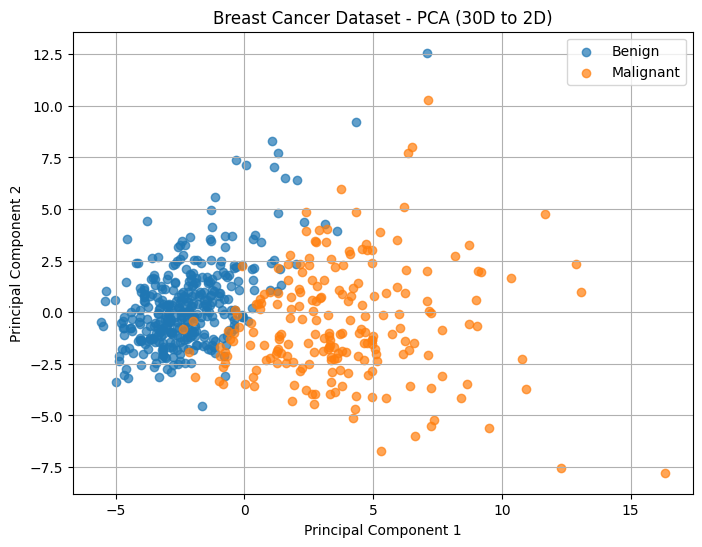

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# Load dataset
data = load_breast_cancer()

X = data.data
y = 1 - data.target  # 0 = Benign, 1 = Malignant

print("Original Shape:", X.shape)

# Standardize the features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Apply PCA
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

print("\nPCA Shape:", X_pca.shape)

# Explained variance
print("\nExplained Variance Ratio:", pca.explained_variance_ratio_)
print("Total Variance Retained:", pca.explained_variance_ratio_.sum())

# Create DataFrame for visualization
pca_df = pd.DataFrame(X_pca, columns=["PC1", "PC2"])
pca_df["Target"] = y

print("\nFirst 5 PCA Rows:")
print(pca_df.head())

# Visualize
plt.figure(figsize=(8, 6))

plt.scatter(
    pca_df[pca_df["Target"] == 0]["PC1"],
    pca_df[pca_df["Target"] == 0]["PC2"],
    label="Benign",
    alpha=0.7
)

plt.scatter(
    pca_df[pca_df["Target"] == 1]["PC1"],
    pca_df[pca_df["Target"] == 1]["PC2"],
    label="Malignant",
    alpha=0.7
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("Breast Cancer Dataset - PCA (30D to 2D)")
plt.legend()
plt.grid(True)
plt.show()